# Demo: mooring processing pipeline

End-to-end mooring processing with `oceanarray.run`, run on the committed `dune2_1_2026` test fixture so this notebook
reproduces from a clean checkout — no external data or mounted drive needed.

The pipeline stages:

1. **Stage 1** — raw instrument files → CF-NetCDF (`_stage1.nc`), faithful to raw.
2. **Stage 2** — trim to the deployment window + linear clock-drift correction (`_stage2.nc`).
3. **Stage 3** — QC flags, pressure interpolation, BEAM→ENU rotation + magnetic
   declination, derived variables (`_stage3.nc`).
4. **Stack** — interpolate every instrument onto a common time grid (`_stack.nc`).
5. **Grid** — interpolate the stack onto a regular pressure grid (`_grid.nc`).

`dune2_1_2026` is a two-instrument mooring (a SeaBird MicroCAT and a Nortek Aquadopp).

In [1]:
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr

import oceanarray as oa

plt.style.use("default")

## Set up a scratch workspace

The committed fixtures are read-only inputs. We copy the mooring YAML into a
temporary processing directory and run the pipeline there, reading the raw
instrument files straight from the fixture tree.

In [ ]:
repo_root = Path.cwd() if (Path.cwd() / "tests").is_dir() else Path.cwd().parent
raw_dir = (repo_root / "tests/fixtures/raw").resolve()          # parent of dune2_1_2026/
proc_fixture = (repo_root / "tests/fixtures/proc/dune2_1_2026").resolve()
mooring_name = "dune2_1_2026"

scratch = Path(tempfile.mkdtemp(prefix="demo_mooring_"))
(scratch / mooring_name).mkdir(parents=True)
shutil.copy(proc_fixture / f"{mooring_name}.mooring.yaml", scratch / mooring_name)
print(f"raw inputs : {raw_dir}")
print(f"proc (scratch): {scratch}")

## Run the pipeline

`oa.run` takes the mooring's `*.mooring.yaml` and runs stages 1–3, then the stack and
the grid, returning every file it wrote or kept. `oa.process` runs the stages alone;
`oa.report` builds the HTML pages.

In [3]:
files = oa.run(
    scratch / mooring_name / f"{mooring_name}.mooring.yaml",
    raw_dir=raw_dir,
    dt_seconds=600,
    force=True,
)
print(f"\n{len(files)} files:", *[f.name for f in files], sep="\n  ")

Stage 1 for mooring: dune2_1_2026

--- microcat 2941 ---


  temperature: degC -> degree_Celsius (x1)


Creating output file: dune2_1_2026_2941_stage1.nc

--- aquadopp 9920* ---


  depth: meters -> m (x1)


  heading: degrees -> degree (x1)


  pitch: degrees -> degree (x1)


... (19 outputs left out)

9920: east_velocity_qc=[good=8731, suspect=1087]; north_velocity_qc=[good=8731, suspect=1087]; pressure_qc=[good=9818]; temperature_qc=[good=9818]; up_velocity_qc=[good=8731, suspect=1087]; velocity_beam1_qc=[good=8779, suspect=1039]; velocity_beam2_qc=[good=8779, suspect=1039]; velocity_beam3_qc=[good=8779, suspect=1039]


Stage 3 complete: 2 instrument(s) processed, 2 written
Stage 3: 2 file(s) written, 0 kept (already there; force=True rewrites)
Stack for mooring dune2_1_2026 (dt = 600 s)


Merging 2 instruments onto 1964-point 600s time grid (dune2_1_2026)
  [ 0] aquadopp   s/n 9920      hab= 226.0 m  dt=120s  (stage3)
  [ 1] microcat   s/n 2941      hab= 425.0 m  dt=60s  (stage3)
  NOTE: 22 stage-3 time-series variable(s) not in STACK_VARS were dropped from the stack: amplitude, battery_voltage, conductivity_qc, day, depth, direction, error_code, hour, magnitude, minute, month, second, speed_of_sound, speed_of_sound_used, status_code, velocity_beam1_qc, velocity_beam2_qc, velocity_beam3_qc, velocity_x, velocity_y, velocity_z, year. Add them to oceanarray.pipeline.helpers.STACK_VARS to retain them.
  tilt_from_pressure[0] s/n 9920 (226 m): ref s/n 2941 (425 m, rope=199 m)
Grid for mooring dune2_1_2026 (200–1000 dbar every 20 dbar)
Gridding 2 instruments → 41 pressure levels (200:20:1000 dbar) × 1964 time steps
  NOTE: 5 variable(s) excluded from gridding (listed in _GRID_EXCLUDE): heading, pitch, roll, tilt_from_pressure, velocity_flag



8 files:
  dune2_1_2026_2941_stage1.nc
  dune2_1_2026_9920_stage1.nc
  dune2_1_2026_2941_stage2.nc
  dune2_1_2026_9920_stage2.nc
  dune2_1_2026_2941_stage3.nc
  dune2_1_2026_9920_stage3.nc
  dune2_1_2026_stack.nc
  dune2_1_2026_grid.nc


## The stacked product

`_stack.nc` holds every instrument on one time axis, stacked along `N_LEVELS`
(ordered deep-first). Each level keeps its own pressure record.

dims: {'time': 1964, 'N_LEVELS': 2}
variables: ['temperature', 'temperature_qc', 'salinity', 'salinity_qc', 'conductivity', 'pressure', 'pressure_qc', 'east_velocity', 'north_velocity', 'up_velocity', 'current_speed', 'current_direction', 'east_velocity_qc', 'north_velocity_qc', 'up_velocity_qc', 'heading', 'pitch', 'roll', 'sigma0', 'velocity_flag', 'tilt_from_pressure', 'tilt_pressure_ref_hab', 'tilt_pressure_ref_serial', 'serial_number', 'InstrDepth', 'clock_offset', 'start_time', 'end_time', 'clock_drift_seconds', 'magnetic_declination', 'SENSOR_TEMP_2941', 'SENSOR_CNDC_2941']


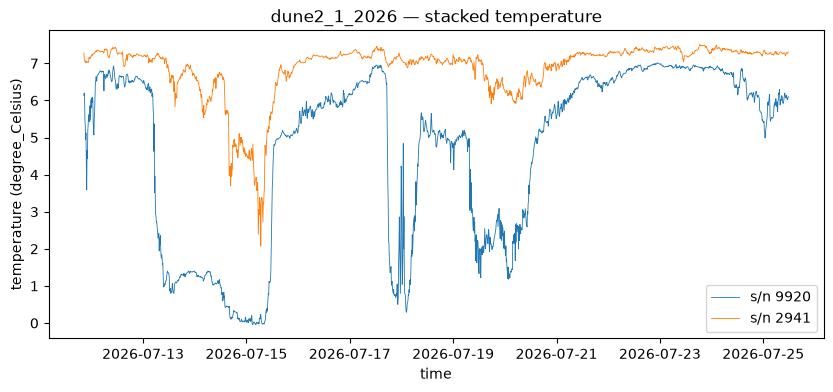

In [4]:
out = scratch / mooring_name
stack = xr.open_dataset(out / f"{mooring_name}_stack.nc", engine="netcdf4", decode_timedelta=False)
print("dims:", dict(stack.sizes))
print("variables:", list(stack.data_vars))

fig, ax = plt.subplots(figsize=(10, 4))
for lev in range(stack.sizes["N_LEVELS"]):
    serial = str(stack["serial"].values[lev]) if "serial" in stack else f"level {lev}"
    ax.plot(stack["time"], stack["temperature"].isel(N_LEVELS=lev), lw=0.6, label=f"s/n {serial}")
ax.set_xlabel("time")
ax.set_ylabel("temperature (degree_Celsius)")
ax.set_title(f"{mooring_name} — stacked temperature")
ax.legend()
plt.show()

## The pressure-gridded product

`_grid.nc` interpolates the stack onto a regular pressure axis — a `(time, pressure)`
field per variable, ready for sectioning.

dims: {'time': 1964, 'pressure': 41}
variables: ['temperature']


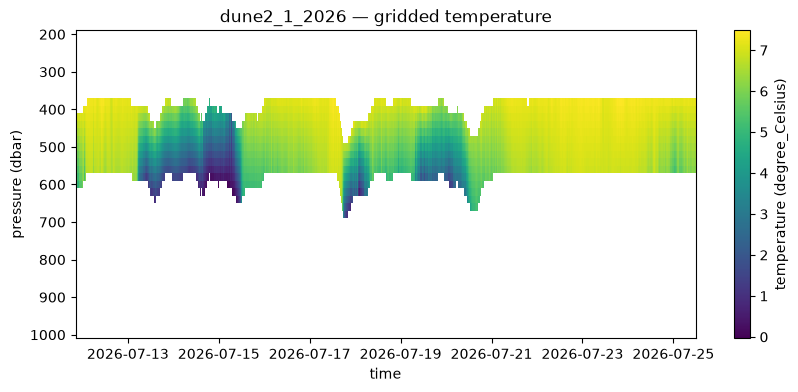

In [5]:
grid = xr.open_dataset(out / f"{mooring_name}_grid.nc", engine="netcdf4", decode_timedelta=False)
print("dims:", dict(grid.sizes))
print("variables:", list(grid.data_vars))

fig, ax = plt.subplots(figsize=(10, 4))
m = ax.pcolormesh(grid["time"], grid["pressure"], grid["temperature"].T, shading="auto")
ax.invert_yaxis()
ax.set_xlabel("time")
ax.set_ylabel("pressure (dbar)")
ax.set_title(f"{mooring_name} — gridded temperature")
fig.colorbar(m, ax=ax, label="temperature (degree_Celsius)")
plt.show()

stack.close()
grid.close()

The same call runs on any mooring with a `*.mooring.yaml` and raw instrument files
under `raw_dir`; point them at a cruise tree to process real data.